<a href="https://colab.research.google.com/github/Abdoulaye279/Financial-Engineering/blob/main/var-es-sp500/portfolio_var_es.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# VaR and Expected Shortfall of a portfolio: S&P 500 and Apple

This notebook extends `sp500_var_es.ipynb` from one asset to a portfolio: 50% in the S&P 500 and 50% in Apple, rebalanced every day. With two assets the question is no longer only "how fat are the tails" but also "how do the two assets move together, especially on bad days".

I look at:
1. the correlation between the two assets and how it changes over time
2. whether they crash together more often than a normal (Gaussian) model says
3. how much diversification really reduces the risk, and which asset the risk comes from
4. a backtest of seven VaR/ES models on the portfolio, from 2004 to 2026

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
from risk import var_es_hist, backtest, portfolio_backtest, kupiec, christoffersen

def load(path):
    df = pd.read_csv(path)
    df["Date"] = pd.to_datetime(df["Date"].str[:10])
    return df.set_index("Date")["Close"]

prices = pd.concat({"spx": load("../black-scholes-sp500/data/sp500.csv"),
                    "aapl": load("data/aapl.csv")}, axis=1).dropna()
rets = np.log(prices).diff().dropna()          # daily log returns of each asset
w = np.array([0.5, 0.5])
port = np.log1p((np.exp(rets) - 1) @ w)        # portfolio log return (weights apply to simple returns)

print(len(rets), "days, from", rets.index[0].date(), "to", rets.index[-1].date())
print("annual vol S&P 500:", round(rets.spx.std() * np.sqrt(252), 3),
      " Apple:", round(rets.aapl.std() * np.sqrt(252), 3),
      " portfolio:", round(port.std() * np.sqrt(252), 3))

6761 days, from 2000-01-04 to 2026-11-19
annual vol S&P 500: 0.192  Apple: 0.394  portfolio: 0.26


The Apple prices in the file are already adjusted for its 4 stock splits. Apple is about twice as volatile as the index. The portfolio volatility is below the average of the two (0.29), which is the diversification effect.

## 1. Correlation over time

correlation over the full period: 0.558
  2000-2004: 0.46
  2005-2009: 0.58
  2010-2014: 0.54
  2015-2019: 0.67
  2020-2026: 0.75


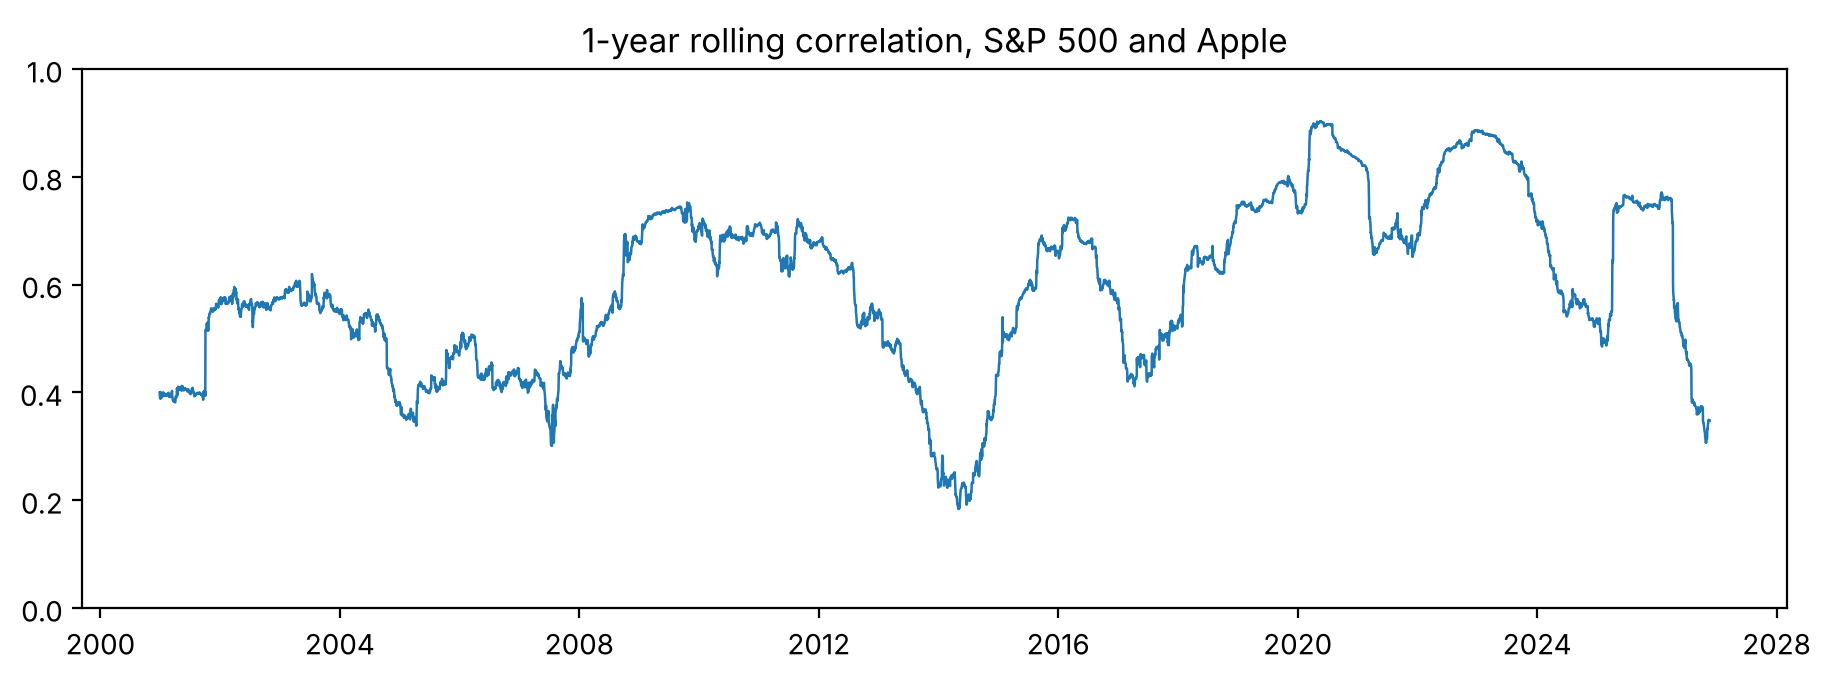

min: 0.18 2014-05-02  max: 0.9 2020-05-22


In [ ]:
print("correlation over the full period:", round(rets.corr().iloc[0, 1], 3))
for a, b in [(2000, 2004), (2005, 2009), (2010, 2014), (2015, 2019), (2020, 2026)]:
    print(f"  {a}-{b}: {rets.loc[str(a):str(b)].corr().iloc[0, 1]:.2f}")

roll_corr = rets.spx.rolling(250).corr(rets.aapl)
fig, ax = plt.subplots(figsize=(11, 3.5))
ax.plot(roll_corr, lw=0.9)
ax.set_title("1-year rolling correlation, S&P 500 and Apple")
ax.set_ylim(0, 1)
plt.show()
print("min:", round(roll_corr.min(), 2), roll_corr.idxmin().date(), " max:", round(roll_corr.max(), 2), roll_corr.idxmax().date())

The correlation is far from constant. It goes from about 0.2 in 2014 to 0.9 in May 2020, then stays high until 2023 and falls back to about 0.35 at the end of 2026. On average it has gone up (0.46 in the early 2000s, 0.75 over 2020-2026), partly for a mechanical reason: Apple has become one of the biggest companies in the index, so when Apple moves, the S&P 500 moves with it. It also jumps quickly in crises, for example from about 0.4 to 0.7 during 2008. For a risk model, this means a correlation estimated on the last 4 years can be quite wrong.

## 2. Do they crash together?

A correlation of 0.6 says nothing about the extremes. To look at the tails I use the tail dependence: among the days when the S&P 500 is in its worst q% of days, how often is Apple also in its worst q%? Under independence it would be q. I compare with a Gaussian copula with the same rank correlation, which is what a normal model implicitly assumes.

In [ ]:
u = rets.rank(pct=True)                                   # ranks between 0 and 1
rho = np.sin(np.pi / 2 * stats.kendalltau(rets.spx, rets.aapl)[0])   # Gaussian correlation matching Kendall's tau
gauss = stats.multivariate_normal([0, 0], [[1, rho], [rho, 1]])
for q in [0.05, 0.01]:
    lower = ((u.spx <= q) & (u.aapl <= q)).mean() / q
    upper = ((u.spx >= 1 - q) & (u.aapl >= 1 - q)).mean() / q
    normal = gauss.cdf([stats.norm.ppf(q)] * 2) / q
    print(f"worst {q:.0%} days: both crash {lower:.3f}   (Gaussian: {normal:.3f})   both jump {upper:.3f}")

worst 5% days: both crash 0.376   (Gaussian: 0.326)   both jump 0.340
worst 1% days: both crash 0.281   (Gaussian: 0.202)   both jump 0.296


On the 1% worst days, the two assets fall together 28% of the time, against 20% for a Gaussian model with the same correlation: joint crashes are about 40% more frequent than a normal model expects. The same happens on the up side (both jump together 30% of the time), so the dependence is strong in both tails, not only in crashes. A normal model therefore underestimates the risk of the portfolio twice: fat tails for each asset, and too few joint extremes.

## 3. Diversification and where the risk comes from

In [ ]:
var_spx, es_spx = var_es_hist(rets.spx.values)
var_aapl, es_aapl = var_es_hist(rets.aapl.values)
var_p, es_p = var_es_hist(port.values)
print(f"historical VaR 99%:  S&P 500 {var_spx:.2%}  Apple {var_aapl:.2%}  portfolio {var_p:.2%}")
print(f"weighted sum of the two VaRs (no diversification): {0.5 * var_spx + 0.5 * var_aapl:.2%}")
print(f"diversification gain on the VaR: {1 - var_p / (0.5 * var_spx + 0.5 * var_aapl):.1%}")

def es_contrib(simple_rets, port_rets):
    # contribution of each asset to the ES: its average weighted loss on the worst 1% portfolio days
    tail = simple_rets[port_rets <= np.quantile(port_rets, 0.01)]
    c = -(tail * w).mean()
    return c / c.sum()

simple = np.exp(rets) - 1
print()
print("share of the ES (whole period):", es_contrib(simple, port).round(3).to_dict())
print("share of the ES (since 2010):  ", es_contrib(simple.loc["2010":], port.loc["2010":]).round(3).to_dict())

historical VaR 99%:  S&P 500 3.46%  Apple 6.37%  portfolio 4.25%
weighted sum of the two VaRs (no diversification): 4.92%
diversification gain on the VaR: 13.4%

share of the ES (whole period): {'spx': 0.316, 'aapl': 0.684}
share of the ES (since 2010):   {'spx': 0.399, 'aapl': 0.601}


Putting both assets in one portfolio cuts the 99% VaR by about 13% compared to holding the risks separately. It helps, but much less than the 0.56 correlation would suggest on calm days, because on the worst days the two assets tend to fall together.

Even with half of the money in each, Apple brings about two thirds of the expected shortfall (68% over the whole period, 60% since 2010). Equal weights in money are far from equal weights in risk. A portfolio with equal risk contributions would need a much smaller Apple weight.

## 4. Backtest of seven models

Five models are the ones from the single-asset notebook, applied directly to the portfolio return as if it were one asset. Two models look at the assets separately:
- EWMA (RiskMetrics): an exponentially weighted covariance matrix (lambda = 0.94) and a normal VaR. This is the classic bank model from the 1990s.
- Multivariate FHS: one GARCH per asset, then each past day's pair of standardised residuals is rescaled by today's two volatilities and turned into a portfolio return. It keeps each asset's own volatility and the real joint tails, without assuming any distribution.

Same rules as before: 1000-day window, GARCH refitted every 250 days, VaR and ES at 99% for the next day.

In [ ]:
bt1 = backtest(port, alpha=0.99, window=1000, refit=250)
bt2 = portfolio_backtest(rets, w, alpha=0.99, window=1000, refit=250)
bt = pd.concat([bt1, bt2.drop(columns="ret")], axis=1)
models = {"normal": "Normal", "hist": "Historical", "garch": "GARCH", "fhs": "FHS", "evt": "GARCH-EVT",
          "ewma": "EWMA", "mfhs": "Multivariate FHS"}

print(len(bt), "days tested, expected breaches:", round(0.01 * len(bt)))
print()
for m, name in models.items():
    breach = bt["ret"] < -bt[f"var_{m}"]
    loss = -bt["ret"][breach]
    ratio = loss.mean() / bt[f"es_{m}"][breach].mean()
    print(f"{name:16s} breaches={breach.sum():4d} ({100*breach.mean():.2f}%)  "
          f"Kupiec p={kupiec(breach.values)[1]:.3f}  Christoffersen p={christoffersen(breach.values)[1]:.3f}  "
          f"loss/ES={ratio:.2f}")

5761 days tested, expected breaches: 58

Normal           breaches= 109 (1.89%)  Kupiec p=0.000  Christoffersen p=0.000  loss/ES=1.28
Historical       breaches=  76 (1.32%)  Kupiec p=0.020  Christoffersen p=0.000  loss/ES=1.03
GARCH            breaches= 109 (1.89%)  Kupiec p=0.000  Christoffersen p=0.532  loss/ES=1.14
FHS              breaches=  78 (1.35%)  Kupiec p=0.010  Christoffersen p=0.406  loss/ES=1.02
GARCH-EVT        breaches=  73 (1.27%)  Kupiec p=0.050  Christoffersen p=0.326  loss/ES=1.04
EWMA             breaches= 106 (1.84%)  Kupiec p=0.000  Christoffersen p=0.477  loss/ES=1.18
Multivariate FHS breaches=  74 (1.28%)  Kupiec p=0.038  Christoffersen p=0.341  loss/ES=1.00


I get:
- Normal, GARCH and EWMA, the three models with a normal distribution, have almost twice too many breaches (1.8 to 1.9%) and an ES 14 to 28% too small. GARCH and EWMA at least get independent breaches because their volatility adapts every day.
- Historical: 1.3% of breaches but they come in clusters, the same problem as for the S&P 500 alone.
- The three GARCH models with a non-normal tail (FHS, GARCH-EVT, multivariate FHS) have independent breaches and an ES almost exactly right (ratio 1.00 to 1.04), but about 1.3% of breaches instead of 1%. The Kupiec test rejects them or is at the limit (p between 0.01 and 0.05).

So on the full period no model passes everything. To see where the extra breaches come from, I count them by year (plot below) and redo the Kupiec test without 2008.

### Breaches over time

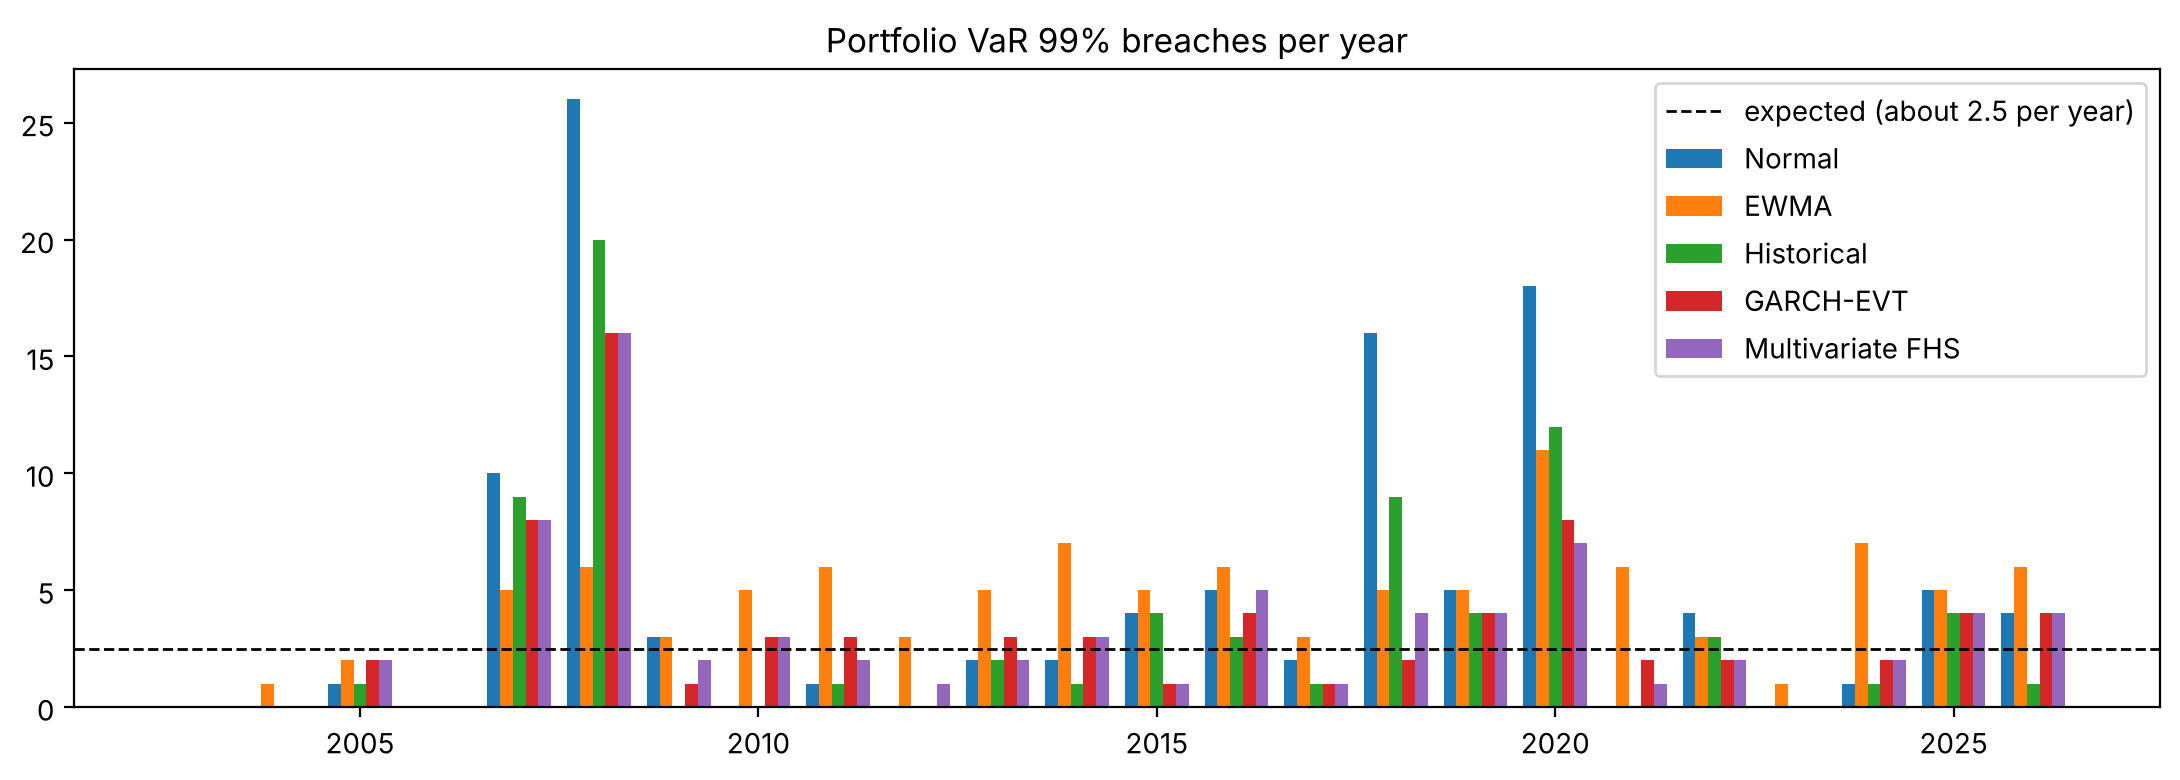

In [ ]:
fig, ax = plt.subplots(figsize=(11, 4))
years = sorted(set(bt.index.year))
show = ["normal", "ewma", "hist", "evt", "mfhs"]
width = 0.16
for i, m in enumerate(show):
    per_year = (bt["ret"] < -bt[f"var_{m}"]).groupby(bt.index.year).sum().reindex(years, fill_value=0)
    ax.bar(np.array(years) + (i - 2) * width, per_year, width, label=models[m])
ax.axhline(2.5, color="k", ls="--", lw=1, label="expected (about 2.5 per year)")
ax.set_title("Portfolio VaR 99% breaches per year")
ax.legend()
plt.tight_layout()
plt.show()

In [ ]:
for m in ["fhs", "evt", "mfhs"]:
    breach = bt["ret"] < -bt[f"var_{m}"]
    rest = breach[breach.index.year != 2008]
    print(f"{models[m]:16s} breaches in 2008: {breach[breach.index.year == 2008].sum():3d}   "
          f"without 2008: {rest.sum()} ({100*rest.mean():.2f}%)  Kupiec p={kupiec(rest.values)[1]:.3f}")

FHS              breaches in 2008:  18   without 2008: 60 (1.09%)  Kupiec p=0.511
GARCH-EVT        breaches in 2008:  16   without 2008: 57 (1.03%)  Kupiec p=0.796
Multivariate FHS breaches in 2008:  16   without 2008: 58 (1.05%)  Kupiec p=0.695


The extra breaches all come from 2008: the three GARCH models with a non-normal tail have 16 to 18 breaches that year instead of about 2.5. Without 2008 they are at 1.03 to 1.09% and pass the Kupiec test easily. In autumn 2008 both assets crashed at the same time and their correlation jumped, faster than a model fitted on the previous 4 calm years could follow. Outside this crisis, the models are well calibrated.




- The correlation between Apple and the S&P 500 is not stable: from 0.2 to 0.9 depending on the year, with a clear upward trend.
- The two assets crash together about 40% more often than a Gaussian model with the same correlation predicts, so the diversification gain is only about 13% on the 99% VaR.
- With 50% of the money, Apple brings about two thirds of the tail risk.
- On the backtest, the three models with a normal distribution (including RiskMetrics) underestimate the risk by a lot. The GARCH models with a non-normal tail give the right ES and independent breaches. They have slightly too many breaches over the full period (about 1.3%), but all the excess comes from 2008: without that year they are at 1.03 to 1.09%.

